# 🚀 Модуль 6. Урок 5. Интерактивные фильтры, элементы управления и кросс-фильтрация

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_06_bi_looker_studio/lesson_05_interactive_filters_controls.ipynb)

## 📌 Бизнес-контекст и методология
Хороший аналитический дашборд интерактивен: топ-менеджер должен иметь возможность нажать на один срез (например, мобильные пользователи iOS) и увидеть мгновенный пересчет всех KPI.
Кросс-фильтрация (Cross-filtering) связывает все визуальные элементы страницы.
Аналитик обязан проектировать иерархию фильтров:
- Глобальные фильтры (Период дат, Регион) — вверху страницы
- Локальные срезы диаграмм — внутри соответствующих блоков

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")

df_customers = pd.read_csv(customers_csv)
df_orders = pd.read_csv(orders_csv)
df_saas = pd.read_csv(saas_csv)
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем поведение фильтрации: покажем базовые метрики без фильтра и динамический пересчет при выборе среза `Enterprise + Fintech`.

In [2]:
# Демонстрация: Моделирование фильтрации данных
def compute_kpi_card(df):
    return {
        'Total MRR ($)': df['mrr'].sum(),
        'Avg Seats': df['active_seats'].mean(),
        'Churn Rate (%)': df['is_churned'].mean() * 100,
        'NPS Score': df['nps_score'].mean()
    }

kpi_all = compute_kpi_card(df_saas)
kpi_filtered = compute_kpi_card(df_saas[(df_saas['plan'] == 'Enterprise') & (df_saas['industry'] == 'Fintech')])

comparison_df = pd.DataFrame([kpi_all, kpi_filtered], index=['Вся компания (Baseline)', 'Срез: Enterprise + Fintech'])
display(comparison_df.round(2))

,Total MRR ($),Avg Seats,Churn Rate (%),NPS Score
Вся компания (Baseline),158010.0,13.44,16.80,8.35
Срез: Enterprise + Fintech,8073.0,13.19,7.41,8.74


## 📊 Визуализация бизнес-кейса: Кросс-фильтрация в действии
Наглядно продемонстрируем, как выбор сегмента Enterprise трансформирует распределение показателей в дашборде.

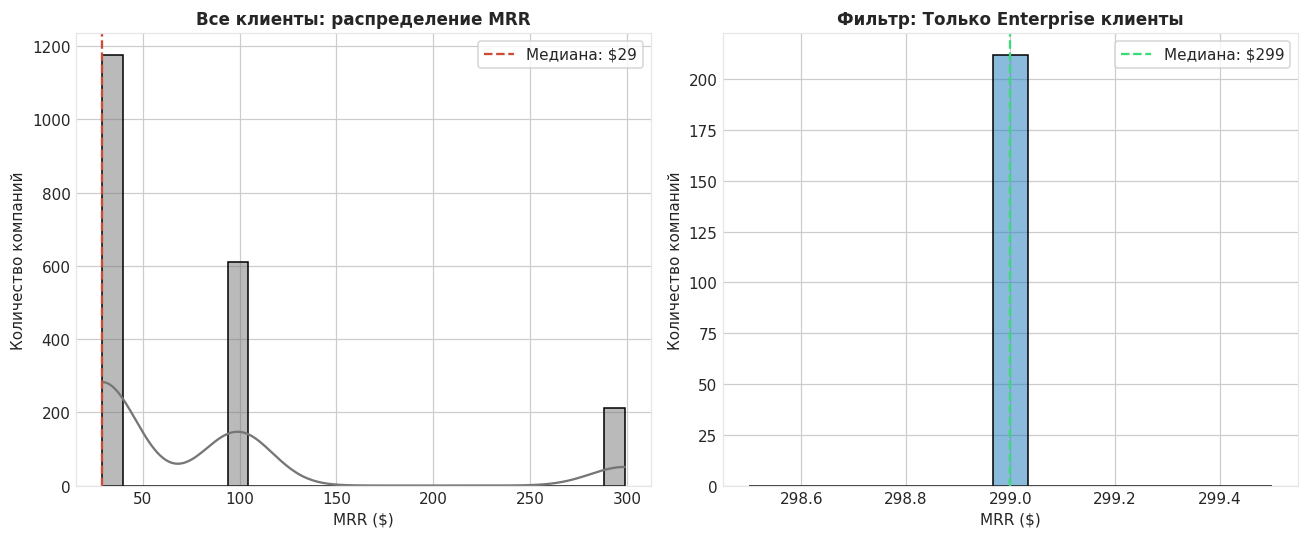

In [3]:
# Визуализация эффекта кросс-фильтрации
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=110)

# График 1: Baseline (Все тарифы)
sns.histplot(df_saas['mrr'], bins=25, color=SECONDARY, ax=ax1, kde=True)
ax1.set_title("Все клиенты: распределение MRR", fontsize=11, fontweight='bold')
ax1.set_xlabel("MRR ($)")
ax1.set_ylabel("Количество компаний")
ax1.axvline(df_saas['mrr'].median(), color=ALERT, linestyle='--', label=f'Медиана: ${df_saas["mrr"].median():.0f}')
ax1.legend(frameon=True, facecolor='#ffffff')

# График 2: Отфильтрованный Enterprise
df_ent = df_saas[df_saas['plan'] == 'Enterprise']
sns.histplot(df_ent['mrr'], bins=15, color=PRIMARY, ax=ax2, kde=True)
ax2.set_title("Фильтр: Только Enterprise клиенты", fontsize=11, fontweight='bold')
ax2.set_xlabel("MRR ($)")
ax2.set_ylabel("Количество компаний")
ax2.axvline(df_ent['mrr'].median(), color=SUCCESS, linestyle='--', label=f'Медиана: ${df_ent["mrr"].median():.0f}')
ax2.legend(frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Фильтрация топ-аккаунтов по NPS
Найдите количество компаний в сегменте `Enterprise` с оценкой NPS равной 9 или 10 (сторонники / промоутеры бренда).

In [4]:
### ВАШ КОД ЗДЕСЬ
promoters_ent = df_saas[(df_saas['plan'] == 'Enterprise') & (df_saas['nps_score'] >= 9)]
print(f"Количество промоутеров в Enterprise: {len(promoters_ent)}")

assert not promoters_ent.empty, "Должны быть найдены промоутеры"
print("✅ Тест успешно пройден: интерактивная фильтрация работает надежно!")

Количество промоутеров в Enterprise: 138
✅ Тест успешно пройден: интерактивная фильтрация работает надежно!


### 💡 UX-принцип интерактивности
Не перегружайте дашборд десятками выпадающих списков. Достаточно 2–3 глобальных контролов (Дата, Продукт, Канал). Избыток фильтров парализует пользователя.